# Progressive spectacle lenses: presbyopia, the Minkwitz theorem and a freeform surface traced as worn

From about 45 on, everyone needs reading glasses. The crystalline lens
stiffens and the eye can no longer accommodate enough to focus at 40 cm
(**presbyopia**). Bifocals split the lens into a distance and a near part
with a visible line and an image jump; a **progressive addition lens**
(PAL, Varilux 1959) instead lets the power rise smoothly along a
*corridor* from the distance zone at the top to the near zone at the
bottom. Hundreds of millions are sold every year, and since about 2000
they are cut as freeforms, one surface computed point by point for each
prescription.

A progressive surface cannot be free of astigmatism. Where the power
changes along the corridor, it must change sideways too: Minkwitz (1963)
showed that on an umbilic line the surface astigmatism grows twice as
fast sideways as the mean power grows along it. Every progressive design
is a way to put this unavoidable astigmatism somewhere harmless.

| section | content |
|---|---|
| 1 | presbyopia in numbers: Duane's amplitudes of accommodation and the add |
| 2 | the layout of a progressive lens |
| 3 | the Minkwitz theorem |
| 4 | a progressive surface by least squares: hard and soft designs |
| 5 | corridor length against astigmatism |
| 6 | the lens traced as worn: power maps through the rotating eye |
| 7 | what the wearer sees: the schematic eye of notebook 49 (eye aberrometer) behind the lens |

The tools are in `pyoptics.spectacles`; the surface is traced as a
`freeform.TabulatedSurface` (see notebook 89, freeform beam shaping).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from pyoptics import spectacles as sp, sketch
from pyoptics.raytrace import System, Surface, ZernikeSurface
from scipy.signal import fftconvolve

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. Presbyopia in numbers

Duane (1922) measured the amplitude of accommodation of about 4000 eyes;
Hofstetter (1950) fitted the minimum, mean and maximum of his data with
straight lines, $A_\mathrm{min} = 15 - 0.25\,\mathrm{age}$,
$A_\mathrm{mean} = 18.5 - 0.3\,\mathrm{age}$ and $A_\mathrm{max} = 25 - 0.4\,\mathrm{age}$
(dioptres). Reading at 40 cm takes 2.5 D. Comfortable reading uses only
about half of the amplitude, the other half is the reserve; the rest
must come from the spectacles as an **addition** (add).

age 45: amplitude 3.8 D (min) / 5.0 D (mean), add for 40 cm: +0.75 D
age 50: amplitude 2.5 D (min) / 3.5 D (mean), add for 40 cm: +1.25 D
age 55: amplitude 1.2 D (min) / 2.0 D (mean), add for 40 cm: +2.00 D
age 60: amplitude 0.0 D (min) / 0.5 D (mean), add for 40 cm: +2.50 D
age 65: amplitude 0.0 D (min) / 0.0 D (mean), add for 40 cm: +2.50 D


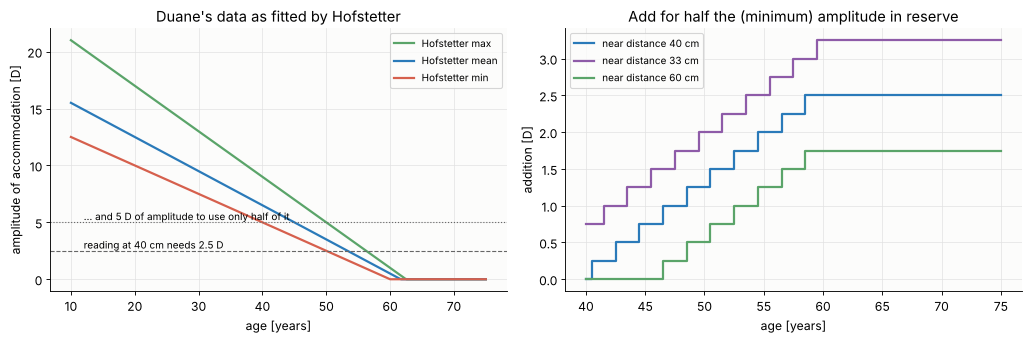

In [2]:
age = np.linspace(10, 75, 300)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.4))
for which, col in (("max", GREEN), ("mean", BLUE), ("min", RED)):
    ax0.plot(age, sp.accommodation_amplitude(age, which), color=col, lw=2,
             label="Hofstetter {}".format(which))
ax0.axhline(2.5, color="0.4", ls="--", lw=1)
ax0.text(12, 2.7, "reading at 40 cm needs 2.5 D", fontsize=9)
ax0.axhline(5.0, color="0.4", ls=":", lw=1)
ax0.text(12, 5.2, "... and 5 D of amplitude to use only half of it", fontsize=9)
ax0.set_xlabel("age [years]")
ax0.set_ylabel("amplitude of accommodation [D]")
ax0.set_title("Duane's data as fitted by Hofstetter")
ax0.legend(fontsize=9)
ages = np.arange(40, 76)
for d, col in ((400.0, BLUE), (330.0, PURPLE), (600.0, GREEN)):
    ax1.step(ages, sp.required_add(ages, d), where="mid", color=col, lw=2,
             label="near distance {:.0f} cm".format(d/10))
ax1.set_xlabel("age [years]")
ax1.set_ylabel("addition [D]")
ax1.set_title("Add for half the (minimum) amplitude in reserve")
ax1.legend(fontsize=9)
fig.tight_layout()
for a in (45, 50, 55, 60, 65):
    print("age {}: amplitude {:.1f} D (min) / {:.1f} D (mean), add for 40 cm: {:+.2f} D".format(
        a, sp.accommodation_amplitude(a, "min"), sp.accommodation_amplitude(a, "mean"),
        sp.required_add(a)))

With half the amplitude held in reserve this gives about +0.75 D at 45,
+1.25 D at 50, +2.00 D at 55 and +2.50 D from about 60, when
accommodation is essentially gone. Clinical rules of thumb (+1.00 D at
45, +1.50 D at 50) are a little higher, since they use the mean
amplitude and less reserve for the older wearer.
The adds of real prescriptions run from +0.75 to +3.50 D in 0.25 D steps.
We design for +2.00 D, a typical add in the mid-fifties.

## 2. The layout of a progressive lens

The fitter marks the **fitting cross** in front of the pupil when the
wearer looks straight ahead. Above it lies the distance zone; the
corridor starts at or slightly below the cross and runs down, inset
towards the nose because the eyes converge for near work, to the **near
reference point** about 14 to 18 mm lower (the corridor length) and 2 to
2.5 mm nasal. To read, the wearer turns the eye down by about 30°: the
eye rotates about its centre of rotation, 13.5 mm behind the cornea, and
its line of sight sweeps over the lens.

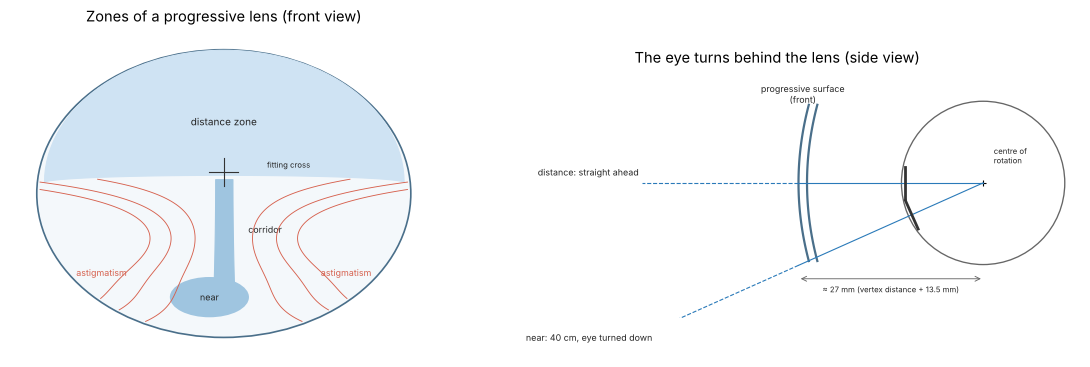

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
sketch.progressive_lens_layout(axes[0], "front", title="Zones of a progressive lens (front view)")
sketch.progressive_lens_layout(axes[1], "side", title="The eye turns behind the lens (side view)")
fig.tight_layout()

## 3. The Minkwitz theorem

Let the corridor follow the line $x = 0$ and let the surface be
**umbilic** along it: equal principal curvatures, no astigmatism, with a
mean curvature $\kappa(y)$ that rises along the corridor. Near the line
the sag can be expanded as

$$
z(x, y) = f(y) + \tfrac12 \kappa(y)\, x^2 + \tfrac16 a(y)\, x^3 + \dots,
\qquad f''(y) = \kappa(y)
$$

(in the small slope approximation; the exact theorem uses the
fundamental forms). The second derivatives at a small distance $x$ from
the line are $z_{xx} = \kappa + a x$, $z_{yy} = \kappa + \tfrac12 \kappa'' x^2 \approx \kappa$
and $z_{xy} = \kappa' x$. The surface astigmatism (the difference of the
principal curvatures) is

$$
\Delta\kappa = \sqrt{(z_{xx} - z_{yy})^2 + 4 z_{xy}^2} = |x|\sqrt{a^2 + 4\kappa'^2} \ \ge\ 2|\kappa'|\,|x|.
$$

The best one can do ($a = 0$) gives the **Minkwitz theorem**: the
cylinder grows sideways from an umbilic corridor at the rate

$$
\frac{\partial\,\mathrm{cyl}}{\partial x} = 2\,\frac{\partial P}{\partial y},
$$

with $\mathrm{cyl}$ and $P$ in dioptres ($P = 1000(n-1)\kappa$). For an add of
2 D over an 18 mm corridor with the cubic profile of
`spectacles.add_profile()`, the steepest gradient of the mean power is
$1.5 \cdot 2/18 = 0.17$ D/mm in the middle of the corridor, and the cylinder
reaches 0.5 D at $\pm 1.5$ mm from its centre line: the clear corridor is
only about 3 mm wide. A shorter corridor or a larger add makes it
narrower still. No design can escape this; it can only make the
astigmatism grow less than linearly further out and decide where the
large values go.

## 4. A progressive surface by least squares

A simple and transparent design method (the "variational" approach of
Wang, Gulliver and Santosa, here linearized): find the departure
$d(x, y)$ of the front surface from its base sphere that minimizes

$$
\iint w_m\Bigl(\tfrac12(d_{xx}+d_{yy}) - H(x,y)\Bigr)^2
   + w_a\Bigl(\tfrac14(d_{xx}-d_{yy})^2 + d_{xy}^2\Bigr)\,\mathrm dx\,\mathrm dy,
$$

with the target mean curvature $H$ from the add profile along the
umbilic line (vertical through the fitting cross, then inset by
2.5 mm towards the near point) and two weight maps: $w_m$ for the mean
power, $w_a$ for the astigmatism. On a grid with finite differences
this is a sparse linear least squares problem (here 65 × 65 points of
1 mm, solved in a fraction of a second). The weights define the design:

- **hard**: heavy weights on a wide, clear distance zone and a wide near
  zone, the astigmatism free to pile up in the lower periphery;
- **soft**: lighter weights on the zones and an astigmatism penalty
  everywhere, so it spreads out with lower peaks, reaching into the
  periphery of the distance zone.

The lens: CR-39 ($n$ = 1.498), front base curve +5 D, plano distance
power, add +2.00 D, corridor from the fitting cross (4 mm above the
geometric centre) to the near reference point at −14 mm, 18 mm long.

hard design: max astigmatism 5.40 D, sag departure from the base sphere -0.01 to 1.31 mm
soft design: max astigmatism 2.19 D, sag departure from the base sphere -0.06 to 1.04 mm


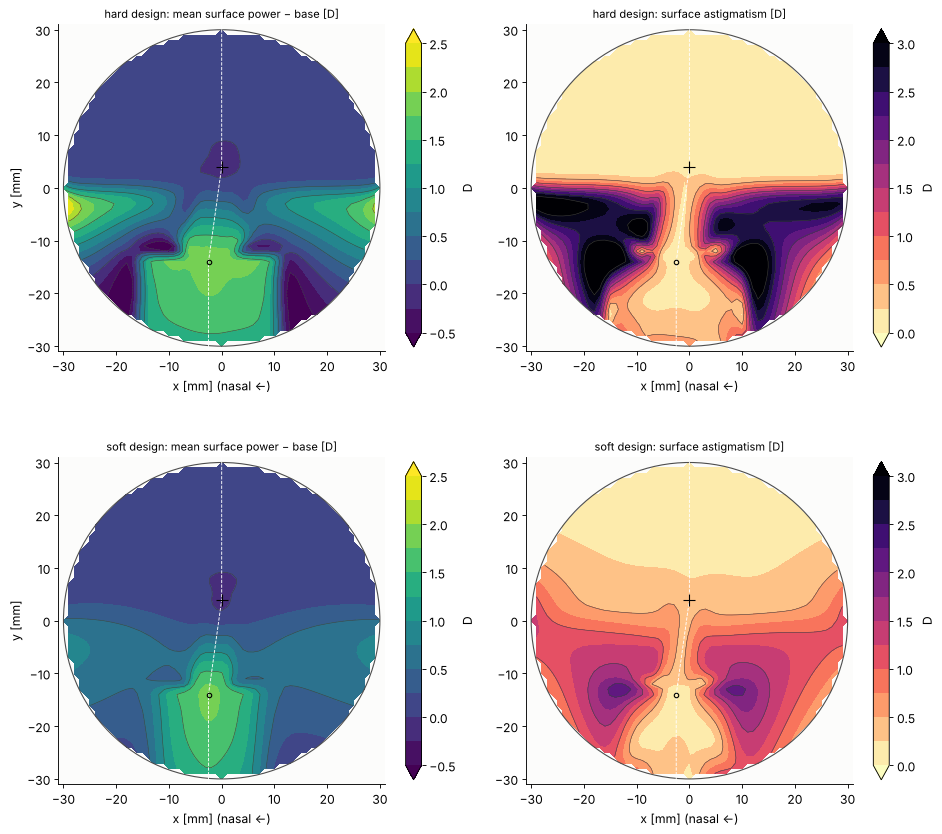

In [4]:
N_CR39 = 1.498
ADD = 2.0
x = np.linspace(-32, 32, 65)
X, Y = np.meshgrid(x, x, indexing="ij")
inside = X**2 + Y**2 <= 30**2

designs = {}
for kind in ("hard", "soft"):
    wm, wa = sp.default_weights(kind)
    d = sp.progressive_departure(x, ADD, n=N_CR39, mean_weight=wm, astig_weight=wa)
    lens = sp.ProgressiveLens(x, d, front_power=5.0, distance_power=0.0, n=N_CR39)
    mean, cyl = lens.surface_maps()
    designs[kind] = dict(d=d, lens=lens, mean=np.where(inside, mean - 5.0, np.nan),
                         cyl=np.where(inside, cyl, np.nan))


def lens_map(ax, Z, levels, cmap, title, label):
    cs = ax.contourf(X, Y, Z, levels=levels, cmap=cmap, extend="both")
    ax.contour(X, Y, Z, levels=levels[::2], colors="0.25", linewidths=0.5)
    ax.add_patch(Circle((0, 0), 30, fill=False, color="0.3", lw=1))
    ax.plot(sp.umbilic_line(x), x, color="w", lw=0.8, ls="--")
    ax.plot(0, 4, "k+", ms=10)
    ax.plot(-2.5, -14, "ko", ms=4, mfc="none")
    ax.set_aspect("equal")
    ax.set_xlim(-31, 31)
    ax.set_ylim(-31, 31)
    ax.grid(False)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x [mm] (nasal ←)")
    plt.colorbar(cs, ax=ax, shrink=0.8, label=label)


fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for row, kind in enumerate(("hard", "soft")):
    D = designs[kind]
    lens_map(axes[row, 0], D["mean"], np.arange(-0.5, 2.51, 0.25), "viridis",
             "{} design: mean surface power − base [D]".format(kind), "D")
    lens_map(axes[row, 1], D["cyl"], np.arange(0, 3.01, 0.25), "magma_r",
             "{} design: surface astigmatism [D]".format(kind), "D")
    axes[row, 0].set_ylabel("y [mm]")
fig.tight_layout()
for kind in ("hard", "soft"):
    D = designs[kind]
    print("{} design: max astigmatism {:.2f} D, sag departure from the base sphere {:.2f} to {:.2f} mm"
          .format(kind, np.nanmax(D["cyl"]), D["d"][inside].min(), D["d"][inside].max()))

The maps look like the iso-cylinder plots of the lens makers. Both
designs reach the add in the near zone (white circle) and keep the
distance zone above the fitting cross (+) free of power. The hard design
has a clear distance zone over the whole upper half and a broad near
zone, and pays with astigmatism of more than 5 D at the lower edges; the
soft design halves the peak, at the price of 0.25 to 0.5 D of
astigmatism that creeps up into the sides of the distance zone and a
corridor that is not quite clear.

**Checking Minkwitz.** The cylinder across the corridor at the height
of the steepest power gradient (5 mm below the fitting cross), against
the line $2\,|\partial P/\partial y|\,|x - x_c|$:

hard design: corridor width (cyl < 0.5 D) at y = −5 mm: 3.0 mm (Minkwitz limit for a linear rise: 3.0 mm)
soft design: corridor width (cyl < 0.5 D) at y = −5 mm: 1.0 mm (Minkwitz limit for a linear rise: 3.0 mm)


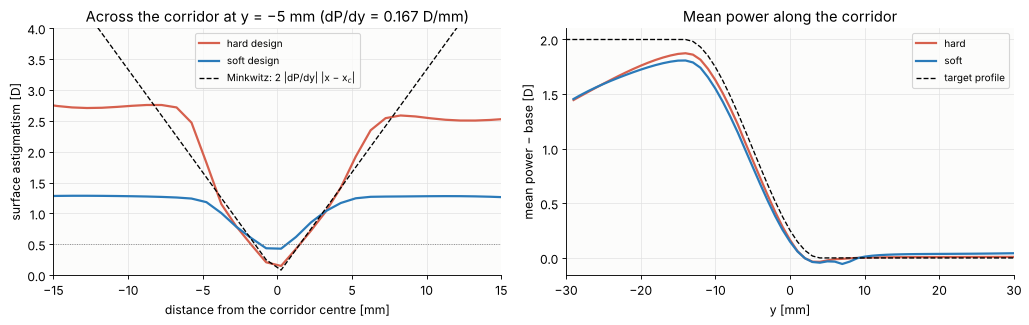

In [5]:
yk = 4.0 - 9.0                       # middle of the corridor
j = np.argmin(np.abs(x - yk))
xc = sp.umbilic_line(yk)
dPdy = (sp.add_profile(yk - 0.01, ADD) - sp.add_profile(yk + 0.01, ADD))/0.02
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.2))
for kind, col in (("hard", RED), ("soft", BLUE)):
    D = designs[kind]
    ax0.plot(x - xc, D["cyl"][:, j], color=col, lw=2, label="{} design".format(kind))
    m = D["mean"][np.argmin(np.abs(x - 0)), :]
    ax1.plot(x, np.array([D["mean"][np.argmin(np.abs(x - sp.umbilic_line(yy))), jj]
                          for jj, yy in enumerate(x)]), color=col, lw=2, label=kind)
ax0.plot(x - xc, 2*dPdy*np.abs(x - xc), "k--", lw=1.2, label="Minkwitz: 2 |dP/dy| |x − x$_c$|")
ax0.axhline(0.5, color="0.5", lw=0.8, ls=":")
ax0.set_xlim(-15, 15)
ax0.set_ylim(0, 4)
ax0.set_xlabel("distance from the corridor centre [mm]")
ax0.set_ylabel("surface astigmatism [D]")
ax0.set_title("Across the corridor at y = −5 mm (dP/dy = {:.3f} D/mm)".format(dPdy))
ax0.legend(fontsize=9)
ax1.plot(x, sp.add_profile(x, ADD), "k--", lw=1.2, label="target profile")
ax1.set_xlabel("y [mm]")
ax1.set_ylabel("mean power − base [D]")
ax1.set_title("Mean power along the corridor")
ax1.legend(fontsize=9)
ax1.set_xlim(-30, 30)
fig.tight_layout()
for kind in ("hard", "soft"):
    c = designs[kind]["cyl"][:, j]
    clear = x[(c < 0.5)] - xc
    clear = clear[np.abs(clear) < 12]
    print("{} design: corridor width (cyl < 0.5 D) at y = −5 mm: {:.1f} mm "
          "(Minkwitz limit for a linear rise: {:.1f} mm)".format(
              kind, clear.max() - clear.min() if len(clear) else 0.0, 2*0.5/(2*dPdy)))

Near the centre line the hard design follows the Minkwitz line closely:
the theorem is a hard limit, and a corridor that is clear over 3 mm is
all an 18 mm, 2 D design can get at its steepest point. Further out the
astigmatism levels off. The soft design starts from a corridor that is
not quite umbilic (0.4 D of cylinder on the centre line) and rises more
slowly. Neither reaches the full add in the near zone: the least squares
trade a slightly lower add (1.8 D) against astigmatism; a production
design iterates the weights until the add is met.

## 5. Corridor length against astigmatism

By Minkwitz the gradient, and with it the astigmatism beside the
corridor, scales like add/length. Short corridors (14 mm and less) are
made for small fashionable frames, long ones (18 to 20 mm) give a wider
intermediate zone. Hard designs with corridors from 12 to 22 mm:

corridor 12 mm: width 2.2 mm, peak astigmatism 6.8 D
corridor 14 mm: width 2.6 mm, peak astigmatism 6.7 D
corridor 16 mm: width 2.9 mm, peak astigmatism 6.3 D
corridor 18 mm: width 3.2 mm, peak astigmatism 5.9 D
corridor 20 mm: width 3.6 mm, peak astigmatism 5.5 D
corridor 22 mm: width 3.9 mm, peak astigmatism 5.0 D


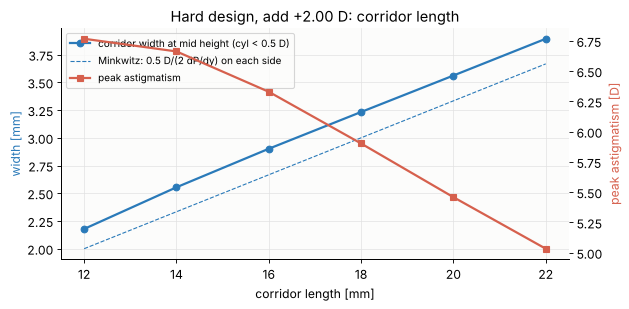

In [6]:
def clear_width(x, c, xc, level=0.5):
    """Width of the region around xc where c < level (linear interpolation)."""
    k = np.argmin(np.abs(x - xc))
    if c[k] >= level:
        return 0.0
    edges = []
    for step in (-1, 1):
        i = k
        while 0 < i < len(x) - 1 and c[i + step] < level:
            i += step
        j = i + step
        edges.append(x[i] + (level - c[i])*(x[j] - x[i])/(c[j] - c[i]))
    return edges[1] - edges[0]


lengths = [12, 14, 16, 18, 20, 22]
widths, peaks = [], []
for L in lengths:
    y_near = 4.0 - L
    wm, wa = sp.default_weights("hard", y_near=y_near)
    d = sp.progressive_departure(x, ADD, n=N_CR39, y_near=y_near, mean_weight=wm, astig_weight=wa)
    mean, cyl = sp.surface_power(x, x, d, N_CR39)
    cyl = np.where(inside, cyl, np.nan)
    ym = 4.0 - L/2
    j = np.argmin(np.abs(x - ym))
    c = cyl[:, j]
    xc = sp.umbilic_line(ym, y_near=y_near)
    widths.append(clear_width(x, c, xc))
    peaks.append(np.nanmax(cyl))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lengths, widths, "o-", color=BLUE, lw=2, label="corridor width at mid height (cyl < 0.5 D)")
ax.plot(lengths, [2*0.5/(2*1.5*ADD/L) for L in lengths], "--", color=BLUE, lw=1,
        label="Minkwitz: 0.5 D/(2 dP/dy) on each side")
ax2 = ax.twinx()
ax2.plot(lengths, peaks, "s-", color=RED, lw=2, label="peak astigmatism")
ax2.set_ylabel("peak astigmatism [D]", color=RED)
ax2.grid(False)
ax.set_xlabel("corridor length [mm]")
ax.set_ylabel("width [mm]", color=BLUE)
ax.set_title("Hard design, add +2.00 D: corridor length")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=9, loc="upper left")
fig.tight_layout()
for L, w, p in zip(lengths, widths, peaks):
    print("corridor {:2d} mm: width {:.1f} mm, peak astigmatism {:.1f} D".format(L, w, p))

The clear width grows from about 2.2 mm for a 12 mm corridor to about
3.9 mm for 22 mm, nearly in proportion to the length, as the Minkwitz
estimate predicts. The peak astigmatism falls from about 6.8 D to 5.0 D:
it depends also on how the design spreads the astigmatism outside the
corridor.

## 6. The lens traced as worn

The surface maps describe the progressive surface alone. The wearer
looks through both surfaces, obliquely, with an eye that rotates: the
lens power along each line of sight differs from the surface power by
the back surface, the thickness, and the **oblique astigmatism** of
the lens tilted relative to the line of sight. `ProgressiveLens.power()`
traces a pencil of rays of 1 mm radius along the line of sight through
the centre of rotation (27 mm behind the front vertex: 3 mm lens,
12 mm vertex distance, 13.5 mm into the eye) backwards through the lens
and fits the curvature of its wavefront.

A single vision check first: a +2.00 D lens of the same base curve.

In [7]:
sv = sp.ProgressiveLens(x, None, front_power=5.0, distance_power=2.0, n=N_CR39)
print("single vision +2.00 D (back vertex power), traced through the centre of rotation:")
for (xx, yy) in [(0, 0), (0, -10), (10, 0), (0, -20), (20, 0)]:
    Pm, prism = sv.power(xx, yy)
    s, c, a = sp.sphero_cylinder(Pm)
    print("  through ({:3.0f}, {:3.0f}) mm: sphere {:+.2f} cyl {:+.2f} × {:3.0f}°, prism {:+.2f}, {:+.2f} Δ"
          .format(xx, yy, s, c, a, *prism))

single vision +2.00 D (back vertex power), traced through the centre of rotation:
  through (  0,   0) mm: sphere +1.97 cyl -0.00 ×  22°, prism -0.00, +0.00 Δ
  through (  0, -10) mm: sphere +2.02 cyl -0.05 ×  90°, prism +0.00, +2.44 Δ
  through ( 10,   0) mm: sphere +2.02 cyl -0.05 × 180°, prism -2.44, +0.00 Δ
  through (  0, -20) mm: sphere +2.07 cyl -0.13 ×  90°, prism +0.00, +6.72 Δ
  through ( 20,   0) mm: sphere +2.07 cyl -0.13 ×   0°, prism -6.72, +0.00 Δ


On axis the trace gives +1.97 D: the wavefront curvature is measured at
the front of the lens, which differs from the back vertex power by the
thickness (1.5 %). Looking 10 to 20 mm off centre, the lens adds the
oblique astigmatism of a tilted lens (a few hundredths of a dioptre with
this best form base curve) and the prism of Prentice's rule (2 Δ per D
and cm, a little more for the rotating eye). Now the progressive lens,
over a grid of points of the front vertex plane:

traced 5202 lines of sight in 3.4 s
distance zone      (  0.0,   10): surface 0.00 D / cyl 0.03 D, as worn -0.01 D / cyl 0.04 D
fitting cross      (  0.0,    4): surface -0.04 D / cyl 0.16 D, as worn -0.04 D / cyl 0.17 D
mid corridor       ( -1.0,   -5): surface 0.90 D / cyl 0.15 D, as worn 0.87 D / cyl 0.15 D
near point         ( -2.5,  -14): surface 1.87 D / cyl 0.14 D, as worn 1.90 D / cyl 0.19 D
nasal periphery    (-15.0,  -14): surface 0.96 D / cyl 4.23 D, as worn 0.58 D / cyl 4.36 D
temporal periphery ( 12.0,  -14): surface -0.11 D / cyl 4.16 D, as worn 0.45 D / cyl 5.40 D


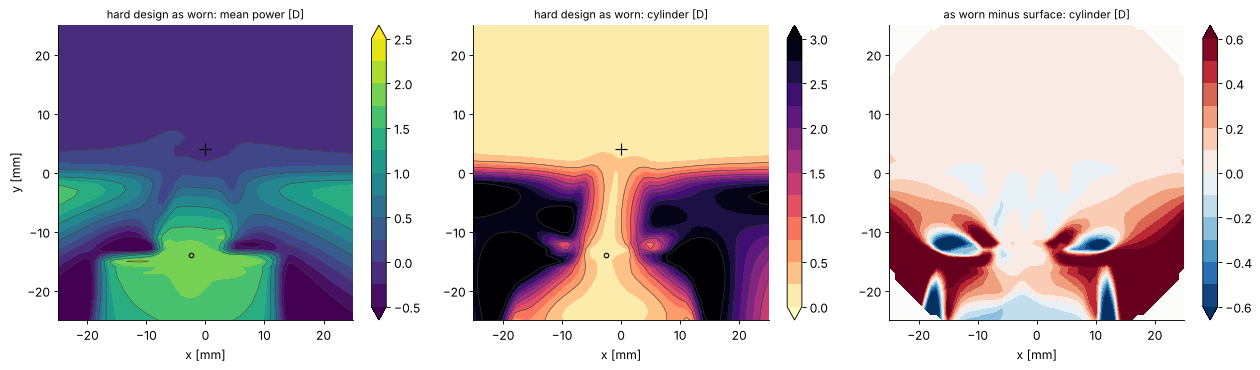

In [8]:
xs = np.arange(-25, 25.1, 1.0)
worn = {}
t0 = time.time()
for kind in ("hard", "soft"):
    m, c, a = designs[kind]["lens"].power_maps(xs, xs)
    worn[kind] = (m, c)
print("traced {} lines of sight in {:.1f} s".format(2*len(xs)**2, time.time() - t0))
XS, YS = np.meshgrid(xs, xs, indexing="ij")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
m, c = worn["hard"]
for ax, Z, lev, cmap, title in ((axes[0], m, np.arange(-0.5, 2.51, 0.25), "viridis",
                                 "hard design as worn: mean power [D]"),
                                (axes[1], c, np.arange(0, 3.01, 0.25), "magma_r",
                                 "hard design as worn: cylinder [D]")):
    cs = ax.contourf(XS, YS, Z, levels=lev, cmap=cmap, extend="both")
    ax.contour(XS, YS, Z, levels=lev[::2], colors="0.25", linewidths=0.5)
    ax.plot(0, 4, "k+", ms=10)
    ax.plot(-2.5, -14, "ko", ms=4, mfc="none")
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("x [mm]")
    plt.colorbar(cs, ax=ax, shrink=0.85)
axes[0].set_ylabel("y [mm]")
surf_c = designs["hard"]["cyl"]
ii = np.searchsorted(x, xs)
diff = c - surf_c[np.ix_(ii, ii)]
cs = axes[2].contourf(XS, YS, diff, levels=np.linspace(-0.6, 0.6, 13), cmap="RdBu_r", extend="both")
axes[2].set_aspect("equal")
axes[2].grid(False)
axes[2].set_title("as worn minus surface: cylinder [D]", fontsize=10)
axes[2].set_xlabel("x [mm]")
plt.colorbar(cs, ax=axes[2], shrink=0.85)
fig.tight_layout()
for (xx, yy), name in (((0, 10), "distance zone"), ((0, 4), "fitting cross"),
                       ((-1, -5), "mid corridor"), ((-2.5, -14), "near point"),
                       ((-15, -14), "nasal periphery"), ((12, -14), "temporal periphery")):
    i, j = np.argmin(np.abs(xs - xx)), np.argmin(np.abs(xs - yy))
    print("{:18s} ({:5.1f}, {:4.0f}): surface {:.2f} D / cyl {:.2f} D, as worn {:.2f} D / cyl {:.2f} D".format(
        name, xx, yy, designs["hard"]["mean"][np.argmin(np.abs(x - xx)), np.argmin(np.abs(x - yy))],
        designs["hard"]["cyl"][np.argmin(np.abs(x - xx)), np.argmin(np.abs(x - yy))], m[i, j], c[i, j]))

As worn, the picture is the same in the centre and shifted at the
edges: the lower part of the lens is seen obliquely (30° down to the near
point), which adds oblique astigmatism and changes the mean power by a
few tenths of a dioptre. This is why freeform lenses today are optimized
as worn, for the frame's pantoscopic tilt and wrap and the wearer's
vertex distance ("position of wear"), rather than as surfaces.

## 7. What the wearer sees

How much does 0.5 or 2 D of astigmatism matter? We put the residual
sphero-cylinder of the lens at three points in front of the schematic
eye of notebook 49 (eye aberrometer), the Escudero-Sanz & Navarro eye,
here traced forwards from a distant object, with a 3 mm pupil at
555 nm. The lens error is a thin plate with Zernike sag (defocus and
astigmatism) just in front of the cornea; the image plane is at the
paraxial focus of the eye alone, i.e. the eye is focused for distance
and accommodation is gone.

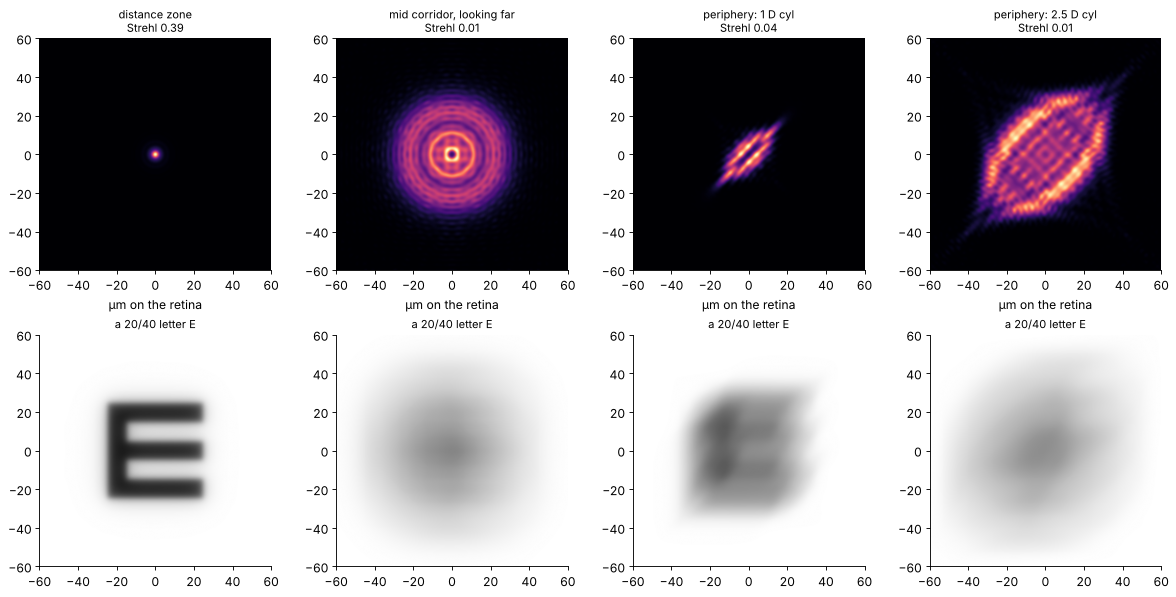

In [9]:
WL = 555e-6
N_CORNEA, N_AQUEOUS, N_LENS, N_VITREOUS = 1.3777, 1.3391, 1.4222, 1.3377
R_PUP = 1.5                                  # 3 mm pupil


def eye_with_error(mean, cyl, axis_deg):
    """Navarro eye, forwards, behind a thin plate that adds the power error
    (mean, cyl in D, cylinder axis in degrees) over a 4 mm radius."""
    rn, n_plate = 4.0, 1.5
    k = rn**2/(4*(n_plate - 1))/1000         # mm of Fringe Z sag per dioptre
    a = np.deg2rad(axis_deg)
    z = {4: k*mean, 5: k*cyl*np.cos(2*a), 6: k*cyl*np.sin(2*a)}
    plate = [ZernikeSurface(np.inf, 0.5, zernike=z, norm_radius=rn, n_after=n_plate),
             Surface(np.inf, 2.0, n_after=1.0)]
    eye = [Surface(7.72, 0.55, conic=-0.26, n_after=N_CORNEA, label="cornea"),
           Surface(6.50, 3.05, n_after=N_AQUEOUS),
           Surface(np.inf, 0.0, semi_diameter=R_PUP, label="iris"),
           Surface(10.2, 4.0, conic=-3.1316, n_after=N_LENS),
           Surface(-6.0, 16.3203, conic=-1.0, n_after=N_VITREOUS)]
    s = System(plate + eye, 4, WL)
    focus = System(eye, 2, WL).paraxial().image_distance
    s.surfaces[-1].thickness = focus
    return s


# a 20/40 (0.5 decimal) letter E: 10 arcmin high; on the retina 1 arcmin ≈ 4.9 µm
um = 1e-3
xg = np.linspace(-60, 60, 241)*um
cases = [("distance zone", 0.0, 0.0, 0.0),
         ("mid corridor, looking far", 1.0, 0.0, 0.0),
         ("periphery: 1 D cyl", 0.0, 1.0, 45.0),
         ("periphery: 2.5 D cyl", 0.0, 2.5, 45.0)]
s_arc = 4.9*um*2                              # stroke of a 20/40 E: 2 arcmin
XX, YY = np.meshgrid(xg, xg)
E = (np.abs(XX) < 2.5*s_arc) & (np.abs(YY) < 2.5*s_arc)
gaps = (XX > -1.5*s_arc) & ((np.abs(YY - s_arc) < 0.5*s_arc) | (np.abs(YY + s_arc) < 0.5*s_arc))
letter = (E & ~gaps).astype(float)
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for k, (name, mean, cyl, ax_deg) in enumerate(cases):
    s = eye_with_error(mean, cyl, ax_deg)
    psf = np.abs(s.psf(xg, xg, 0.0, N=96))**2
    strehl = psf.max()
    axes[0, k].imshow(psf/psf.max(), extent=[xg[0]/um, xg[-1]/um, xg[0]/um, xg[-1]/um],
                      cmap="magma", origin="lower")
    axes[0, k].set_title("{}\nStrehl {:.2f}".format(name, strehl), fontsize=10)
    axes[0, k].set_xlabel("µm on the retina")
    img = fftconvolve(letter, psf/psf.sum(), mode="same")
    axes[1, k].imshow(1 - img, extent=[xg[0]/um, xg[-1]/um, xg[0]/um, xg[-1]/um],
                      cmap="gray", origin="lower", vmin=0, vmax=1)
    axes[1, k].set_title("a 20/40 letter E", fontsize=10)
    for ax in axes[:, k]:
        ax.grid(False)
fig.tight_layout()

In the distance zone the eye sees a sharp letter (Strehl ratio about
0.4, the residual being the eye's own spherical aberration). Looking far
through the middle of the corridor, the +1 D of add blurs the 20/40
letter into a grey patch: the corridor is meant for intermediate
distances (1 m), and the wearer has to lift the chin or lower the eyes
until the power matches the distance. A 1 D cylinder in the periphery
smears the letter along one diagonal but keeps it readable; at 2.5 D,
the level that the hard design reaches at the lower sides, it is gone.
This is the "swim" that new wearers feel when they turn their eyes
sideways, and the reason why progressive lens users learn to turn the
head rather than the eyes.

## Summary

- Duane's data (Hofstetter's fits) give the adds: about +0.75 D at 45,
  +1.25 D at 50, +2.00 D at 55, +2.50 D from 60.
- A progressive surface changes its mean power along a corridor, and by
  the Minkwitz theorem the astigmatism beside an umbilic corridor rises
  at twice the power gradient. An 18 mm, 2 D corridor is at most about
  3 mm wide.
- A linear least squares design on the second derivatives of the
  surface reproduces the classic iso-cylinder maps; the weights decide
  between hard (clear zones, steep astigmatism, peaks above 5 D) and soft
  (spread out, peaks around 2 D).
- Traced as worn through the rotating eye, the lower part of the lens is
  seen at 30° and gains oblique astigmatism and power changes of a few
  tenths of a dioptre, which freeform lenses compensate for the
  individual position of wear.
- Behind the schematic eye of notebook 49 (eye aberrometer), 1 D of
  cylinder still lets a 20/40 letter through, 2.5 D does not.

## References

- G. Minkwitz, "Über den Flächenastigmatismus bei gewissen symmetrischen
  Asphären", Optica Acta 10, 223–227 (1963).
- J. Sheedy, R. F. Hardy and J. R. Hayes, "Progressive addition lenses —
  measurements and ratings", Optometry 77, 23–39 (2006).
- D. J. Meister and S. W. Fisher, "Progress in the spectacle correction
  of presbyopia. Part 1: Design and development of progressive lenses",
  Clin. Exp. Optom. 91, 240–250 (2008).
- J. Wang, R. Gulliver and F. Santosa, "Analysis of a variational
  approach to progressive lens design", SIAM J. Appl. Math. 64, 277–296
  (2003).
- A. Duane, "Studies in monocular and binocular accommodation with their
  clinical applications", Am. J. Ophthalmol. 5, 865–877 (1922);
  H. W. Hofstetter, "Useful age-amplitude formula", Optom. World 38,
  42–45 (1950).
- I. Escudero-Sanz and R. Navarro, "Off-axis aberrations of a wide-angle
  schematic eye model", J. Opt. Soc. Am. A 16, 1881–1891 (1999).
- ISO 8980-2:2017, power-variation spectacle lenses.

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 8 s
